# E3 - Andor EMCCD, long exposures over time

Back-to-back 30 min exposures of an injured leaf in 2 % H2O2 on the Andor iXon DU888 EMCCD (4x4 binning, EM gain 300, 1 MHz, deep cooling) until the leaf dries out (~12 h). Same protocol as E4 on the ToupTek. **Run this first**: it answers whether the sample glows above background and how strongly, which sets the frame time for E1 and tells us whether the ToupTek has a chance.

**Before you start**

- Nothing in this notebook moves the stage, the focus or switches a light. Position and focus the sample by hand, close the enclosure, switch the illumination off.
- Run once with `DRY_RUN = True` (three 5 s frames through the whole chain), then set it to `False`.
- The camera settings are applied by property name. A wrong name stops the notebook before anything changes and prints the names the camera has.
- The Andor runs on `AndorServerManager` (setup `FRAME_6_ANDORSERVER.json`); snaps go through `RecordingController.startSnap`: one exposure at a time on andor-server, cancellable, temperature readable while it integrates. **Stop the Andor live view in ImSwitch** before starting, otherwise a snap returns the last streamed frame instead of a fresh exposure.

The summary reports sample minus background in ADU/px/s with its standard error over the frames; `significance_sigma` above ~3 means the leaf glows.

## 1 Connect

In [1]:
from pathlib import Path
import biophoton as bp

# None = $IMSWITCH_API_URL, which ImSwitch sets for the notebooks it serves itself.
# From another computer use the address you open in the browser, e.g. "http://192.168.1.20/imswitch/api".
IMSWITCH_URL = "http://localhost"
IMSWITCH_URL = "http://192.168.178.50"
PORT = 8001
PORT = 80
client = bp.connect(IMSWITCH_URL, PORT)
print("Connected to", client.base_uri, "| detectors:", client.settingsManager.getDetectorNames())

Connected to http://192.168.178.50:80/imswitch/api | detectors: ['Andor', 'ObservationCamera']


## 2 Settings

In [2]:
DETECTOR = "Andor"           # detector name in the setup JSON (FRAME_6_ANDORSERVER.json)
RUN_NAME = "cress_h2o2"
DRY_RUN = False               # True: 3 short frames through the whole chain, marked as dry run

SAMPLE = {
    "species": "Lepidium sativum (garden cress)",
    "treatment": "injured + 2 % H2O2",
    "prepared_at": None,     # ISO time of injury + H2O2, e.g. "2026-10-23T09:40"; plots count from here
    "notes": "",
}

EXPOSURE_S = 30 * 60            # one frame, back to back
DURATION_H = 12              # no new frame starts after this; stop earlier with the Stop cell
CAMERA = {                   # AndorServerManager parameter names, applied in this order
    "output_amplifier": "Electron Multiplying",  # first: switching it resets readout rate + pre-amp gain
    "readout_rate": "1 MHz",
    "gain": 300,                 # EM gain, as in the June data (above 300 ages the EM register faster)
    "binning": 4,                # 4x4: 52 µm super-pixels, 16x the charge per pixel
    "cooler": True,
    "target_temperature": -80,
}
COOLDOWN = {"tolerance_c": 2.0, "timeout_s": 45 * 60}
ENV_PERIOD_S = 30
# Also log the other camera, e.g. [{"label": "toupcam", "url": "http://192.168.1.21/imswitch/api", "detector": None}]
OTHER_SERVERS = []
DATA_ROOT = Path("data")     # run folders go to data/E3_andor_long_exposure/<date>_<RUN_NAME>/

N_FRAMES = None
if DRY_RUN:
    EXPOSURE_S, DURATION_H, N_FRAMES = 5, None, 3

STEPS = [{"label": "frame", "exposure_ms": EXPOSURE_S * 1000, "n_frames": N_FRAMES,
          "duration_s": DURATION_H * 3600 if DURATION_H else None}]
print(f"{'DRY RUN: ' if DRY_RUN else ''}{EXPOSURE_S:g} s frames, "
      f"{f'{N_FRAMES} frames' if N_FRAMES else f'for {DURATION_H} h'} on {DETECTOR}")

1800 s frames, for 12 h on Andor


## 3 Run folder, camera settings, environment log, cooldown

Creates a new run folder (never reuses one), applies `CAMERA` by name and reads it back, starts the environment log and waits for the sensor to reach its set point.

In [3]:
try:
    if acq.running:
        raise RuntimeError("An acquisition is still running in this kernel - stop it first (Stop cell)")
except NameError:
    pass

run = bp.Run("E3_andor_long_exposure", RUN_NAME, DATA_ROOT)
readback = bp.apply_settings(client, DETECTOR, CAMERA)
run.log(f"camera read back: {readback}")
run.update_config(
    kind="timecourse", experiment="E3", title="E3 - Andor EMCCD, long exposures over time",
    description='Back-to-back 30 min exposures of an injured leaf in 2 % H2O2 on the Andor iXon DU888 EMCCD (4x4 binning, EM gain 300, 1 MHz, deep cooling) until the leaf dries out (~12 h). Same protocol as E4 on the ToupTek. **Run this first**: it answers whether the sample glows above background and how strongly, which sets the frame time for E1 and tells us whether the ToupTek has a chance.',
    sample=SAMPLE, server=client.base_uri, detector=DETECTOR, dry_run=DRY_RUN,
    camera_settings=CAMERA, camera_readback=readback, steps=STEPS,
    analysis={"mode": "integrated", "label": "frame", "window_min": 60,
              "e_per_adu": None,   # electrons per count at 1 MHz from the Andor performance sheet
              "em_gain": CAMERA["gain"]},
    rois={"sample": None, "background": None})
run.save_json("camera_start.json", bp.parameters(client, DETECTOR)[1])

env = bp.EnvLogger(run.dir / "environment.csv",
                   bp.env_sources(client, DETECTOR, "andor", OTHER_SERVERS), ENV_PERIOD_S).start()
bp.wait_for_temperature(client, DETECTOR, CAMERA["target_temperature"], log=run.log, **COOLDOWN)

2026-10-27 19:34:50  run folder C:\Users\Martin\ImSwitchConfig\imnotebook\BIOPHOTON\data\E3_andor_long_exposure\2026-10-27_19-34-50_cress_h2o2
2026-10-27 19:34:52  camera read back: {'output_amplifier': 'Electron Multiplying', 'readout_rate': '1 MHz', 'gain': 300, 'binning': 4, 'cooler': True, 'target_temperature': -80}
sensor -79.9 °C, target -80 °C   2026-10-27 19:34:52  sensor at -79.9 °C


-79.89

## 4 Start

Runs in a background thread and returns at once.

In [4]:
acq = bp.Acquisition(run, client, DETECTOR, STEPS, backend="recording", env=env,
                     env_label="andor").start()

2026-10-27 19:34:52  step 0 'frame': 1800 s frames, for 43200 s
2026-10-27 20:04:57  saved frame_0000 (1800 s, median 4027.0)
2026-10-27 20:35:02  saved frame_0001 (1800 s, median 3976.0)
2026-10-27 21:05:06  saved frame_0002 (1800 s, median 3941.0)
2026-10-27 21:35:10  saved frame_0003 (1800 s, median 3951.5)
2026-10-27 22:05:15  saved frame_0004 (1800 s, median 3899.0)
2026-10-27 22:35:20  saved frame_0005 (1800 s, median 3858.0)
2026-10-27 23:05:24  saved frame_0006 (1800 s, median 3885.0)
2026-10-27 23:35:29  saved frame_0007 (1800 s, median 3903.0)
2026-10-28 00:05:33  saved frame_0008 (1800 s, median 3879.0)
2026-10-28 00:35:38  saved frame_0009 (1800 s, median 3897.0)
2026-10-28 01:05:42  saved frame_0010 (1800 s, median 3891.0)
2026-10-28 01:35:46  saved frame_0011 (1800 s, median 3886.0)
2026-10-28 02:05:51  saved frame_0012 (1800 s, median 3869.0)
2026-10-28 02:35:56  saved frame_0013 (1800 s, median 3866.0)
2026-10-28 03:06:00  saved frame_0014 (1800 s, median 3868.0)
2026-1

## 5 Dashboard

Redraws from the files on disk every 15 s. Interrupting it (■) stops only the display; re-run it any time, e.g. after the browser reconnects.

done | step 0 frame 23 | 24 frames


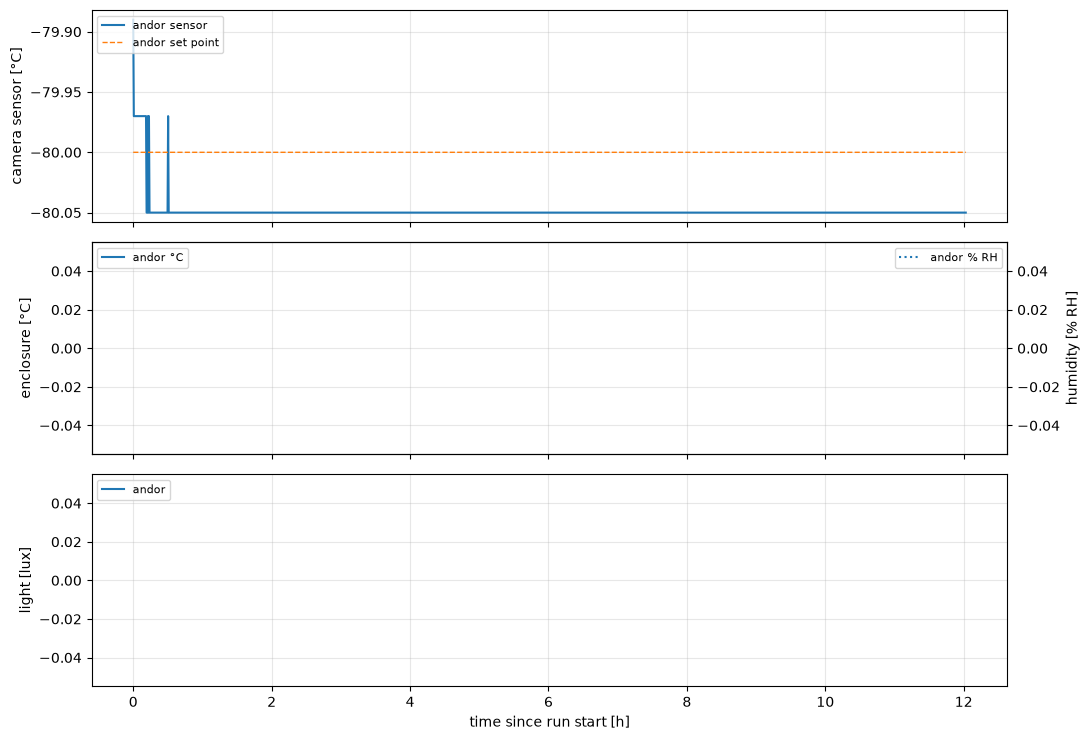

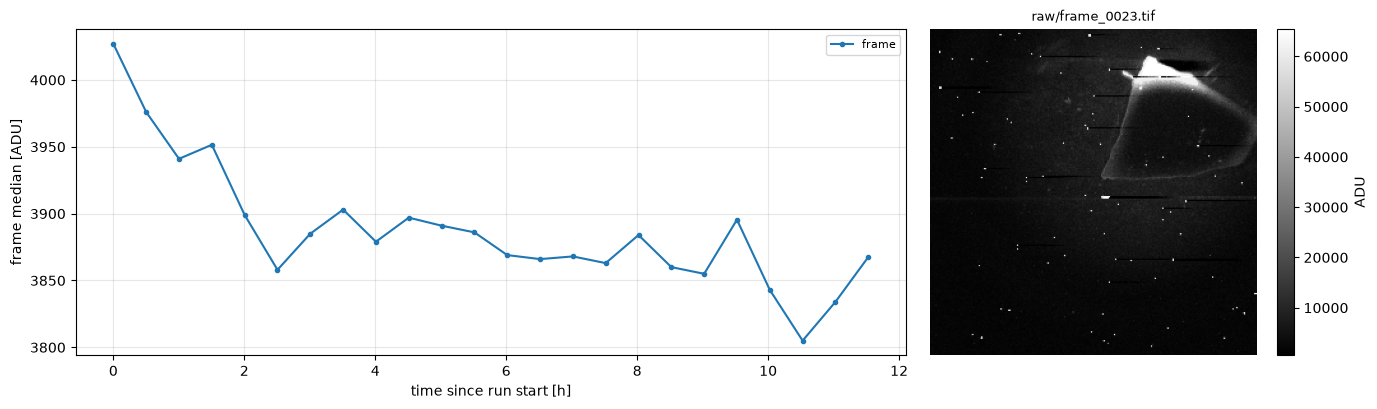

2026-10-28 05:36:21  saved frame_0019 (1800 s, median 3895.5)
2026-10-28 06:06:25  saved frame_0020 (1800 s, median 3843.0)
2026-10-28 06:36:30  saved frame_0021 (1800 s, median 3805.0)
2026-10-28 07:06:34  saved frame_0022 (1800 s, median 3834.0)
2026-10-28 07:36:39  saved frame_0023 (1800 s, median 3867.5)
2026-10-28 07:36:39  acquisition done: 24 frames
acquisition finished: done


In [5]:
bp.dashboard(run.dir, acq, refresh_s=15)

## Stop

Interrupt the dashboard cell first (■): the kernel runs one cell at a time. This cancels the running
exposure on the server. Frames already saved stay on disk.

In [6]:
acq.stop()
print(acq.state)

{'phase': 'done', 'detail': '24 frames', 'step': 0, 'frame': 23, 'error': None, 'started': '2026-10-27T19:34:52', 'finished': '2026-10-28T07:36:39'}


## Finish

Stops the environment log and stores the camera state at the end. Run it after the acquisition has
finished or was stopped.

In [7]:
env.stop()
run.save_json("camera_end.json", bp.parameters(client, DETECTOR)[1])
run.log("run finished")

2026-10-28 07:36:41  run finished


## Analysis and report

Works on any run folder: point `RUN_DIR` at an older run to redraw it. Everything is read from the
files in that folder and written back to it (`figures/`, `analysis.csv`, `summary.json`,
`README.md`), so re-running these cells never loses data.

1. Show a frame and read off a **sample** ROI on the leaf and a **background** ROI next to it, as
   `[x, y, width, height]` in pixels of the saved frame.
2. Store the ROIs and redraw.

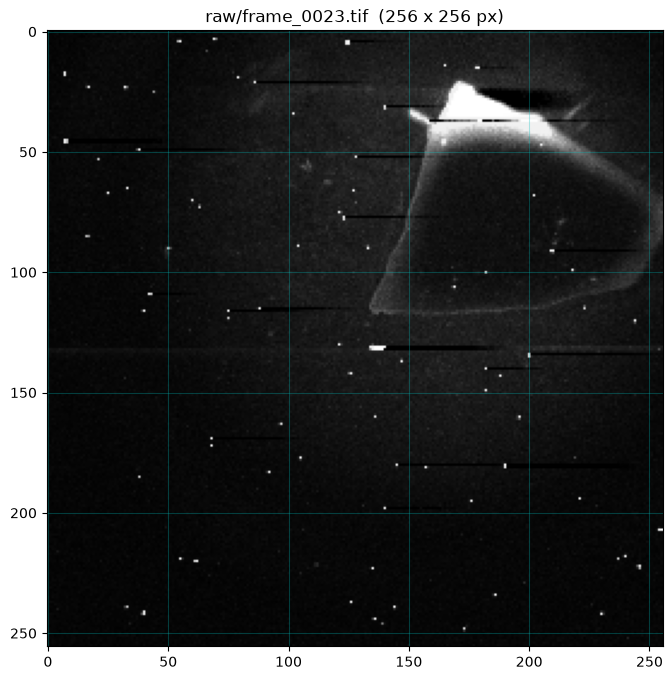

In [8]:
RUN_DIR = run.dir           # or e.g. Path("data/E3_andor_long_exposure/<run folder>")
bp.show_frame(RUN_DIR, index=-1);

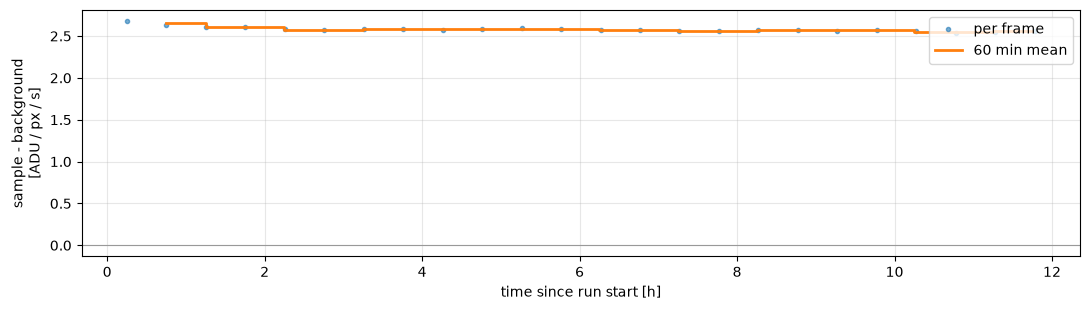

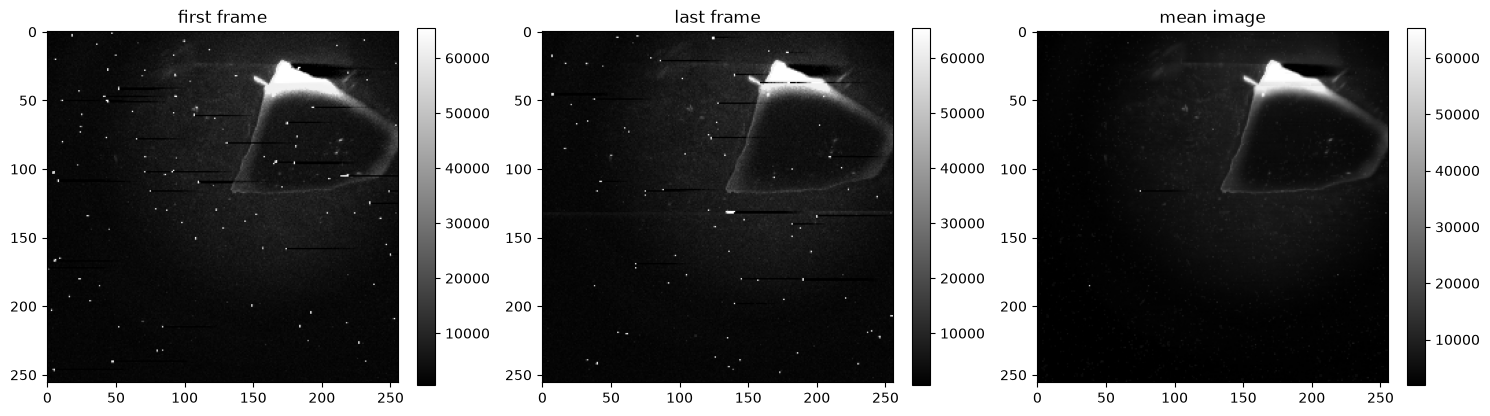

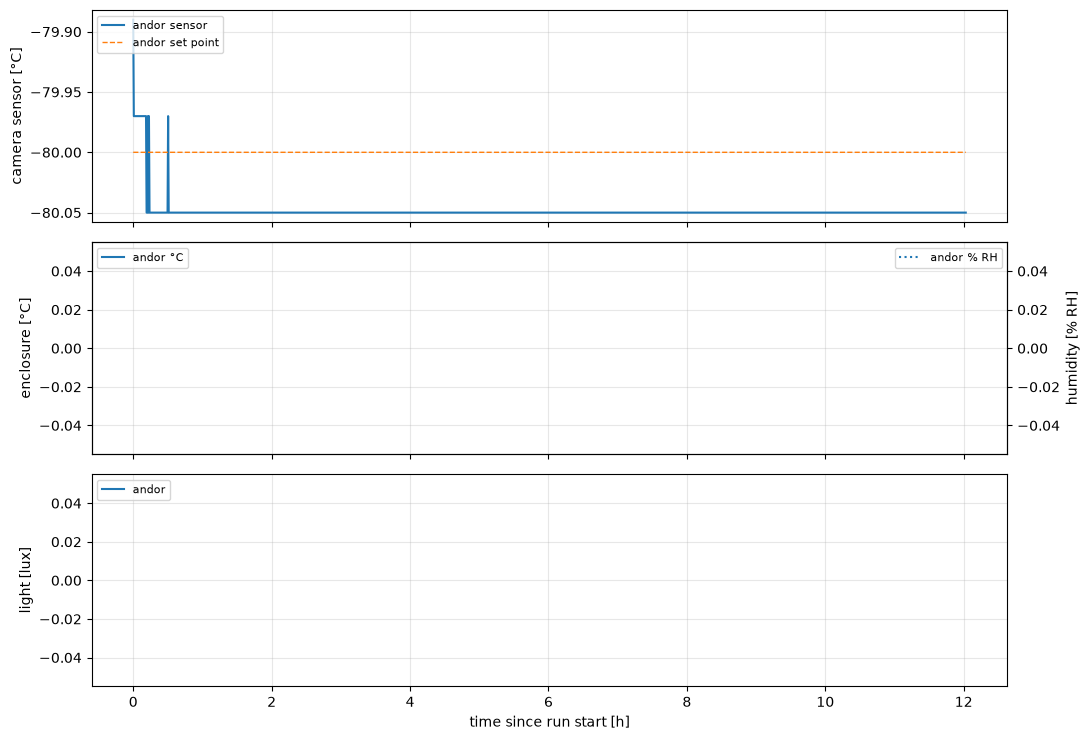

{'frames': 24,
 'mode': 'integrated',
 'unit': 'ADU / px / s',
 'total_exposure_h': 12.0,
 'time_axis': 'since run start',
 'rois': {'sample': None, 'background': None},
 'warnings': ['no sample ROI set: whole frame used',
  'no background ROI or offset: rates include the camera offset'],
 'rate': 2.580371307847192,
 'rate_error': 0.00589172639874948,
 'camera_temperature_c_min_max': [-80.05, -79.89]}

In [9]:
bp.set_rois(RUN_DIR, {"sample": None, "background": None})   # e.g. {"sample": [80, 90, 60, 60], "background": [10, 10, 40, 40]}
summary = bp.redraw(RUN_DIR, show=True)
summary

The run folder now holds `README.md` with this summary and the figures, and `report.ipynb`, which
redraws them from that folder alone (it imports the copy of `biophoton.py` stored with the run).